# Hot Potato Effect Within a Single Tick
## Empirical Investigation Using NASDAQ ITCH 5.0 Order Book Data

**SMMG Research** — Pankaj J. · Bhavik P. · David M.

---

This notebook documents our empirical investigation of the hot potato mechanism
at the intra-tick level using NASDAQ TotalView-ITCH 5.0 full order book data.

**Dataset:** SPY — January 30, 2020 — Full Trading Day (~423 million ITCH packets)
**Parser:** Custom Go-based ITCH 5.0 binary parser → Apache Parquet pipeline

### Contents
1. Dataset overview and pipeline
2. Are odd-lot executions unusual? *(Initial uncertainity)*
3. Odd-lot execution patterns — time of day, quantities, depth
4. Fill-flip detection — methodology, fingerprint filtering, results
5. Time delta analysis — how fast are the flips?
6. Interpretation and significance
7. Further research directions

In [1]:
import polars as pl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams['figure.figsize'] = (13, 5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['font.size'] = 11

df  = pl.read_parquet('executions.parquet')
odd = df.filter(pl.col('is_odd_lot') == True)
rnd = df.filter(pl.col('is_odd_lot') == False)

print('=' * 55)
print('  DATASET — SPY, January 30 2020, Full Day')
print('=' * 55)
print(f'  Total executions     : {len(df):>10,}')
print(f'  Round-lot            : {len(rnd):>10,}  ({len(rnd)/len(df)*100:.1f}%)')
print(f'  Odd-lot              : {len(odd):>10,}  ({len(odd)/len(df)*100:.1f}%)')
print(f'  Unique odd-lot qtys  : {odd["shares_executed"].n_unique():>10,}')
print('=' * 55)

import os
os.makedirs('images', exist_ok=True)


  DATASET — SPY, January 30 2020, Full Day
  Total executions     :     80,910
  Round-lot            :     50,245  (62.1%)
  Odd-lot              :     30,665  (37.9%)
  Unique odd-lot qtys  :        914


---
## 1. Pipeline Description

We built a custom Go parser for NASDAQ ITCH 5.0 binary data. The parser maintains
a **live in-memory order book** and for every execution event writes one enriched
row to Apache Parquet:

| Column | Description |
|--------|-------------|
| `timestamp_ns` | Nanoseconds since midnight — full nanosecond resolution |
| `side` | Side of the **resting** order (B = bid, S = ask) |
| `price` | Execution price in dollars |
| `shares_executed` | Shares consumed in this execution |
| `is_odd_lot` | True if quantity not divisible by 100 |
| `shares_remaining_at_level_after_fill` | Depth still resting at this price level after this fill |
| `num_orders_remaining_at_level_after_fill` | Orders still resting at this level |
| `level_formed_at_ns` | When the first order arrived at this price level |

**Processing stats:** 423 million ITCH packets → 80,910 SPY execution rows → ~40-45 min runtime.

---
## 2. Are Odd-Lot Executions Unusual?

> *Question: "Are quantities like 207, 305 — odd lots — unusual?"*

**Answer: No. Odd-lot executions are not unusual at all.**

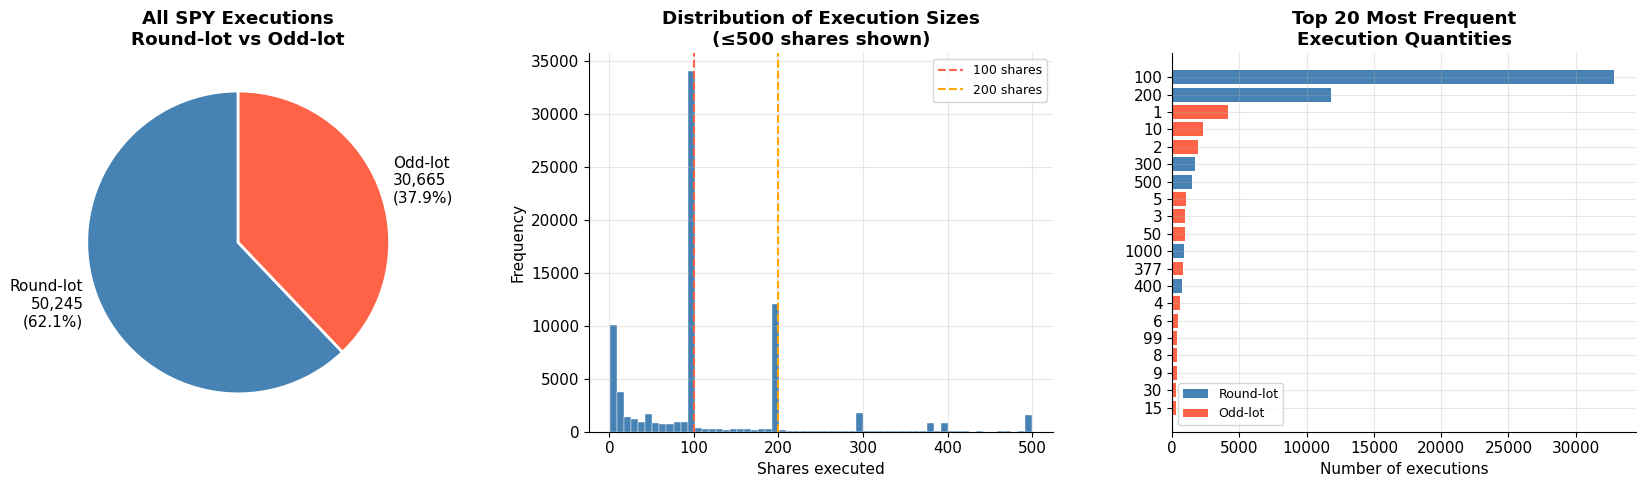

Key finding: 37.9% of all SPY executions were odd-lot.
Odd-lot executions are not unusual — they are a structural feature of modern markets.


In [2]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sizes  = [len(rnd), len(odd)]
labels = [f'Round-lot\n{len(rnd):,}\n({len(rnd)/len(df)*100:.1f}%)',
          f'Odd-lot\n{len(odd):,}\n({len(odd)/len(df)*100:.1f}%)']
axes[0].pie(sizes, labels=labels, colors=['steelblue','tomato'],
            startangle=90, wedgeprops={'edgecolor':'white','linewidth':2})
axes[0].set_title('All SPY Executions\nRound-lot vs Odd-lot', fontweight='bold')

shares = df['shares_executed'].to_numpy()
axes[1].hist(shares[shares <= 500], bins=60, color='steelblue', edgecolor='white', linewidth=0.3)
axes[1].axvline(100, color='tomato', linestyle='--', lw=1.5, label='100 shares')
axes[1].axvline(200, color='orange', linestyle='--', lw=1.5, label='200 shares')
axes[1].set_xlabel('Shares executed'); axes[1].set_ylabel('Frequency')
axes[1].set_title('Distribution of Execution Sizes\n(≤500 shares shown)', fontweight='bold')
axes[1].legend(fontsize=9)

qty_freq = (df.group_by('shares_executed')
              .agg(pl.len().alias('count'))
              .sort('count', descending=True).head(20))
is_odd_bar = [q % 100 != 0 for q in qty_freq['shares_executed'].to_list()]
bar_colors = ['tomato' if o else 'steelblue' for o in is_odd_bar]
axes[2].barh([str(q) for q in qty_freq['shares_executed'].to_list()],
             qty_freq['count'].to_list(), color=bar_colors)
axes[2].set_xlabel('Number of executions')
axes[2].set_title('Top 20 Most Frequent\nExecution Quantities', fontweight='bold')
axes[2].invert_yaxis()
legend_els = [mpatches.Patch(facecolor='steelblue', label='Round-lot'),
              mpatches.Patch(facecolor='tomato', label='Odd-lot')]
axes[2].legend(handles=legend_els, fontsize=9)
plt.tight_layout()
plt.savefig('images/fig1_oddlot_overview.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Key finding: {len(odd)/len(df)*100:.1f}% of all SPY executions were odd-lot.')
print('Odd-lot executions are not unusual — they are a structural feature of modern markets.')

---
## 3. Odd-Lot Execution Patterns

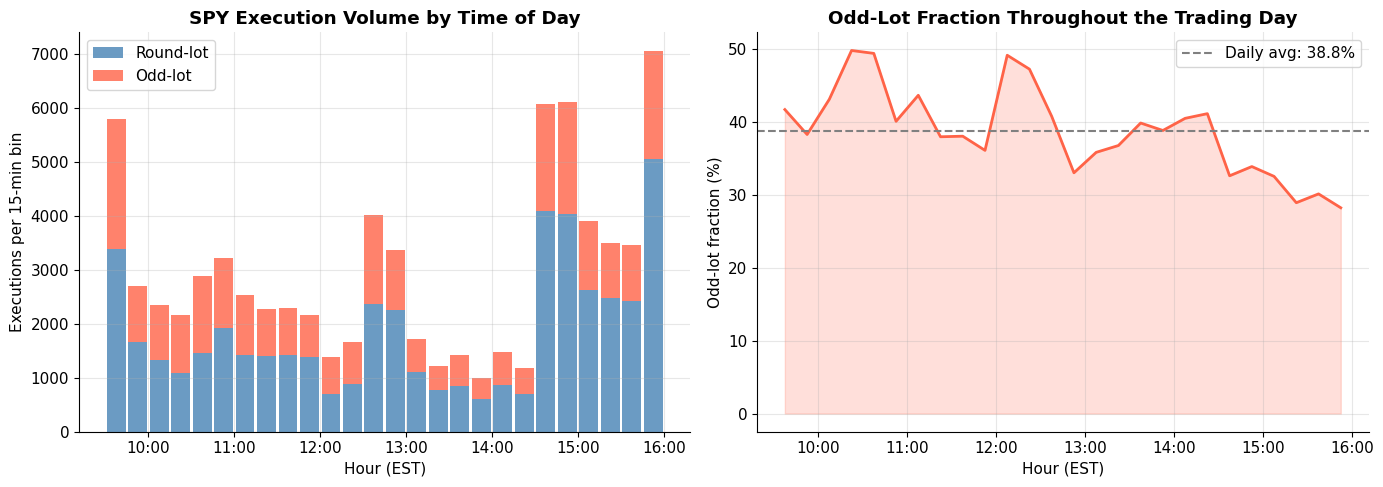

In [3]:
df_h = df.with_columns((pl.col('timestamp_ns') / 1e9 / 3600).alias('hour'))
odd_h = df_h.filter(pl.col('is_odd_lot') == True)['hour'].to_numpy()
rnd_h = df_h.filter(pl.col('is_odd_lot') == False)['hour'].to_numpy()
bins  = np.arange(9.5, 16.1, 0.25)
odd_cnt, _ = np.histogram(odd_h, bins=bins)
rnd_cnt, _ = np.histogram(rnd_h, bins=bins)
bin_c = (bins[:-1] + bins[1:]) / 2
total_cnt = odd_cnt + rnd_cnt
odd_frac  = np.where(total_cnt > 0, odd_cnt / total_cnt * 100, 0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(bin_c, rnd_cnt, width=0.22, label='Round-lot', color='steelblue', alpha=0.8)
axes[0].bar(bin_c, odd_cnt, width=0.22, bottom=rnd_cnt, label='Odd-lot', color='tomato', alpha=0.8)
axes[0].set_xlabel('Hour (EST)'); axes[0].set_ylabel('Executions per 15-min bin')
axes[0].set_title('SPY Execution Volume by Time of Day', fontweight='bold')
axes[0].set_xticks(np.arange(10, 17))
axes[0].set_xticklabels([f'{h}:00' for h in range(10, 17)])
axes[0].legend()

axes[1].plot(bin_c, odd_frac, color='tomato', linewidth=2)
axes[1].fill_between(bin_c, odd_frac, alpha=0.2, color='tomato')
axes[1].axhline(odd_frac.mean(), color='grey', linestyle='--',
                label=f'Daily avg: {odd_frac.mean():.1f}%')
axes[1].set_xlabel('Hour (EST)'); axes[1].set_ylabel('Odd-lot fraction (%)')
axes[1].set_title('Odd-Lot Fraction Throughout the Trading Day', fontweight='bold')
axes[1].set_xticks(np.arange(10, 17))
axes[1].set_xticklabels([f'{h}:00' for h in range(10, 17)])
axes[1].legend()
plt.tight_layout()
plt.savefig('images/fig2_time_of_day.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 4. Fill-Flip Detection

### 4.1 The Hot Potato Mechanism

From Our documented case study (section 2 of the draft paper):

1. Agent rests a **limit sell** at price P — passive, waiting in the ask queue
2. An incoming market buy sweeps the queue in FIFO order — Agent's order is filled — Agent is now **short**
3. Agent immediately flips with a **market buy** to close the short — hitting the **same ask queue at the same price P**
4. This consumes the agent who was **directly behind** in the FIFO queue — the hot potato is passed

In ITCH data, **both events appear as executions on resting sell orders (side = S)**:
- Event 1: Agent's resting sell gets consumed → `side=S, price=P, qty=Q`
- Event 2: Agent's market buy hits the next resting sell → `side=S, price=P, qty=Q`

Same side, same price, same quantity, within milliseconds.

### 4.2 The Odd-Lot Fingerprint

The quantity Q is the identification key. Our paper explains why:

> *"Odd-lot quantities such as 107 are comparatively rare and are therefore unlikely
> to reflect deliberate trade sizing. Instead, their appearance strongly indicates
> a mechanical origin, arising from execution sequencing rather than strategic intent."*

The 107-share residual is generated mechanically by FIFO queue depletion — not chosen.
This makes it a distinctive fingerprint for tracing the fill-flip sequence through data.

### 4.3 The Noise Problem and How We Handle It

Not all odd-lot quantities are equally distinctive. We found that:
- **Quantity = 1** appears 4,170 times — fractional share routing noise
- **Quantity = 50** appears 935 times — deliberate half-lot algorithmic trading
- **Quantity = 377** appears 829 times — a repeating algorithmic strategy

These quantities appear many times at the same price level and would generate
false matches (--regarding fill flip identification). They are not mechanically generated residuals.

**Our fingerprint filter:** We retain only quantities that appear **at most 3 times
at any single price+side level** across the entire trading day.
This gives us 841 genuinely distinctive fingerprint quantities covering 8,343 fills —
quantities that are rare enough that two occurrences at the same price within 1ms
cannot plausibly be coincidental.

In [4]:
# ── Strict set: quantities >= 50 shares, appear at most 3x at any price+side
# (original criterion — conservative, very clean fingerprints)
odd_50 = odd.filter(pl.col('shares_executed') >= 50)

level_max = (odd_50.group_by(['shares_executed', 'price', 'side'])
             .agg(pl.len().alias('n'))
             .group_by('shares_executed')
             .agg(pl.col('n').max().alias('max_at_any_level'))
             .filter(pl.col('max_at_any_level') <= 3))

fingerprint_qtys_strict = level_max['shares_executed'].to_list()
odd_fp_strict = odd_50.filter(pl.col('shares_executed').is_in(fingerprint_qtys_strict))

print('── STRICT fingerprint set ──────────────────────────────')
print(f'  Base: odd-lot fills with qty >= 50 shares : {len(odd_50):,}')
print(f'  Fingerprint quantities (appear <=3x at any level): {len(fingerprint_qtys_strict):,}')
print(f'  Fills in strict set                        : {len(odd_fp_strict):,}')

# ── Lax set: drop qty < 10 and exact multiples of 10 (new suggestion)
# No upper bound on how many times a quantity can appear at a level.
# This captures more potential flips including chains (hot potato passed multiple times).
odd_lax = odd.filter(
    (pl.col('shares_executed') >= 10) &
    (pl.col('shares_executed') % 10 != 0)
)

print()
print('── LAX fingerprint set (new criterion) ─────────────')
print(f'  Drop qty < 10 and exact multiples of 10')
print(f'  Fills in lax set                           : {len(odd_lax):,}')
print()
print('Examples of quantities excluded by lax filter (multiples of 10):')
excluded_lax = odd.filter(
    (pl.col('shares_executed') >= 10) &
    (pl.col('shares_executed') % 10 == 0)
)
print(excluded_lax.group_by('shares_executed').agg(pl.len().alias('n'))
      .sort('n', descending=True).head(8))


── STRICT fingerprint set ──────────────────────────────
  Base: odd-lot fills with qty >= 50 shares : 12,553
  Fingerprint quantities (appear <=3x at any level): 841
  Fills in strict set                        : 8,343

── LAX fingerprint set (new criterion) ─────────────
  Drop qty < 10 and exact multiples of 10
  Fills in lax set                           : 15,174

Examples of quantities excluded by lax filter (multiples of 10):
shape: (8, 2)
┌─────────────────┬──────┐
│ shares_executed ┆ n    │
│ ---             ┆ ---  │
│ i32             ┆ u32  │
╞═════════════════╪══════╡
│ 10              ┆ 2332 │
│ 50              ┆ 935  │
│ 30              ┆ 304  │
│ 20              ┆ 240  │
│ 90              ┆ 239  │
│ 40              ┆ 213  │
│ 60              ┆ 156  │
│ 80              ┆ 133  │
└─────────────────┴──────┘


In [5]:
def detect_fill_flip(fp_df, window_ns):
    """
    Detect fill-flip pairs.
    Both events: same stock, same price, same side, same quantity,
    different match numbers, flip after initiator, within time window.
    """
    initiator = fp_df.select([
        pl.col('timestamp_ns').alias('init_ts'),
        pl.col('stock').alias('init_stock'),
        pl.col('side').alias('init_side'),
        pl.col('price').alias('init_price'),
        pl.col('shares_executed').alias('init_shares'),
        pl.col('match_number').alias('init_match'),
        pl.col('shares_remaining_at_level_after_fill').alias('init_depth_remaining'),
        pl.col('num_orders_remaining_at_level_after_fill').alias('init_orders_remaining'),
    ])
    flip = fp_df.select([
        pl.col('timestamp_ns').alias('flip_ts'),
        pl.col('stock').alias('flip_stock'),
        pl.col('side').alias('flip_side'),
        pl.col('price').alias('flip_price'),
        pl.col('shares_executed').alias('flip_shares'),
        pl.col('match_number').alias('flip_match'),
    ])
    return (
        initiator
        .join(flip,
              left_on =['init_stock','init_price','init_shares','init_side'],
              right_on=['flip_stock','flip_price','flip_shares','flip_side'],
              how='inner')
        .filter(pl.col('init_match') != pl.col('flip_match'))
        .filter(pl.col('flip_ts') > pl.col('init_ts'))
        .filter((pl.col('flip_ts') - pl.col('init_ts')) <= window_ns)
        .with_columns((pl.col('flip_ts') - pl.col('init_ts')).alias('time_delta_ns'))
        .sort('time_delta_ns')
        .unique(subset=['init_match'], keep='first')
    )

windows = [1_000_000, 5_000_000, 10_000_000, 50_000_000]
results_strict = {}
results_lax    = {}
pair_dfs_strict = {}
pair_dfs_lax    = {}

print('── STRICT set results ──────────────────────────────────')
for w in windows:
    p = detect_fill_flip(odd_fp_strict, w)
    results_strict[w] = len(p)
    pair_dfs_strict[w] = p
    base = len(odd_fp_strict)
    print(f'  Window {w/1e6:>4.0f}ms → {len(p):>4} pairs  (hit rate: {len(p)/base*100:.2f}%)')

print()
print('── LAX set results (new criterion) ─────────────────')
for w in windows:
    p = detect_fill_flip(odd_lax, w)
    results_lax[w] = len(p)
    pair_dfs_lax[w] = p
    base = len(odd_lax)
    print(f'  Window {w/1e6:>4.0f}ms → {len(p):>4} pairs  (hit rate: {len(p)/base*100:.2f}%)')

pairs_1ms_strict = pair_dfs_strict[1_000_000]
pairs_1ms_lax    = pair_dfs_lax[1_000_000]

td_strict = pairs_1ms_strict['time_delta_ns'].to_numpy()
td_lax    = pairs_1ms_lax['time_delta_ns'].to_numpy()

print()
print('── 1ms time delta — strict ─────────────────────────────')
print(f'  Min    : {td_strict.min():,} ns = {td_strict.min()/1000:.1f} µs')
print(f'  Median : {int(np.median(td_strict)):,} ns = {np.median(td_strict)/1000:.1f} µs')
print(f'  < 100µs: {(td_strict < 100_000).sum()} pairs ({(td_strict < 100_000).sum()/len(td_strict)*100:.1f}%)')
print(f'  < 500µs: {(td_strict < 500_000).sum()} pairs ({(td_strict < 500_000).sum()/len(td_strict)*100:.1f}%)')

print()
print('── 1ms time delta — lax ────────────────────────────────')
print(f'  Min    : {td_lax.min():,} ns = {td_lax.min()/1000:.1f} µs')
print(f'  Median : {int(np.median(td_lax)):,} ns = {np.median(td_lax)/1000:.1f} µs')
print(f'  < 100µs: {(td_lax < 100_000).sum()} pairs ({(td_lax < 100_000).sum()/len(td_lax)*100:.1f}%)')
print(f'  < 500µs: {(td_lax < 500_000).sum()} pairs ({(td_lax < 500_000).sum()/len(td_lax)*100:.1f}%)')


── STRICT set results ──────────────────────────────────
  Window    1ms →  134 pairs  (hit rate: 1.61%)
  Window    5ms →  154 pairs  (hit rate: 1.85%)
  Window   10ms →  166 pairs  (hit rate: 1.99%)
  Window   50ms →  207 pairs  (hit rate: 2.48%)

── LAX set results (new criterion) ─────────────────
  Window    1ms →  400 pairs  (hit rate: 2.64%)
  Window    5ms →  515 pairs  (hit rate: 3.39%)
  Window   10ms →  571 pairs  (hit rate: 3.76%)
  Window   50ms →  679 pairs  (hit rate: 4.47%)

── 1ms time delta — strict ─────────────────────────────
  Min    : 623 ns = 0.6 µs
  Median : 106,308 ns = 106.3 µs
  < 100µs: 64 pairs (47.8%)
  < 500µs: 121 pairs (90.3%)

── 1ms time delta — lax ────────────────────────────────
  Min    : 561 ns = 0.6 µs
  Median : 106,769 ns = 106.8 µs
  < 100µs: 190 pairs (47.5%)
  < 500µs: 352 pairs (88.0%)


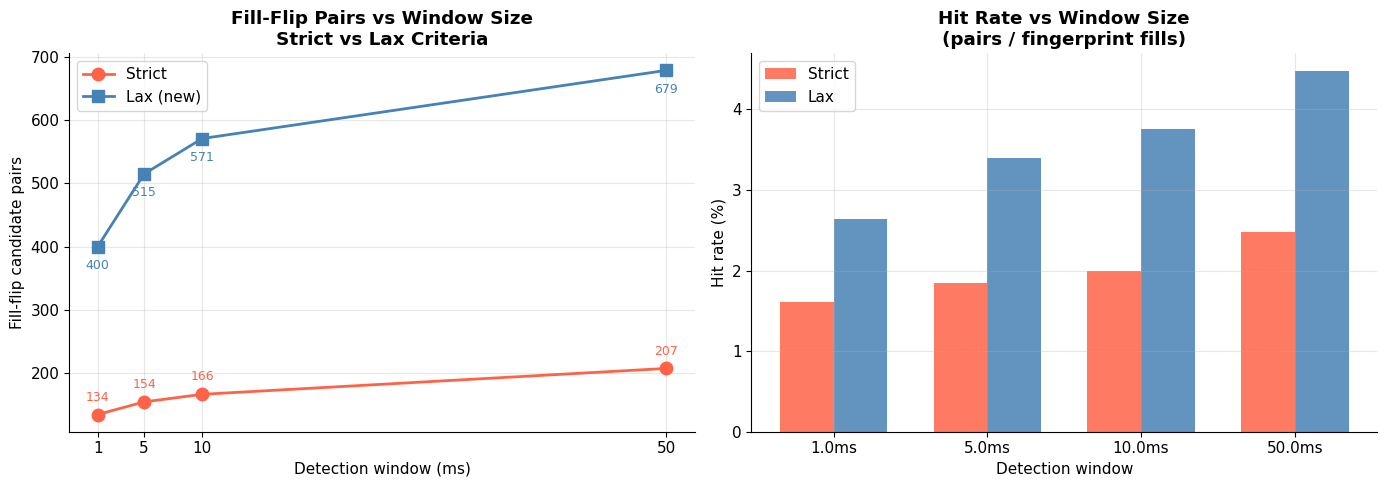

Strict: 50x window expansion → 1.54x more pairs
  → 65% of all detectable pairs occur within the first 1ms

Lax   : 50x window expansion → 1.70x more pairs
  → 59% of all detectable pairs occur within the first 1ms

Both criteria show similar window sensitivity — results are robust across criteria.


In [6]:
windows_ms = [w/1e6 for w in windows]
pf_strict  = [results_strict[w] for w in windows]
pf_lax     = [results_lax[w]    for w in windows]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: both series on same chart
axes[0].plot(windows_ms, pf_strict, 'o-', color='tomato',    lw=2, markersize=9, label='Strict')
axes[0].plot(windows_ms, pf_lax,    's-', color='steelblue', lw=2, markersize=9, label='Lax (new)')
for x, y in zip(windows_ms, pf_strict):
    axes[0].annotate(str(y), (x, y), textcoords='offset points',
                     xytext=(0, 10), ha='center', fontsize=9, color='tomato')
for x, y in zip(windows_ms, pf_lax):
    axes[0].annotate(str(y), (x, y), textcoords='offset points',
                     xytext=(0, -16), ha='center', fontsize=9, color='steelblue')
axes[0].set_xlabel('Detection window (ms)')
axes[0].set_ylabel('Fill-flip candidate pairs')
axes[0].set_title('Fill-Flip Pairs vs Window Size\nStrict vs Lax Criteria', fontweight='bold')
axes[0].set_xticks(windows_ms)
axes[0].legend()

# Right: hit rates side by side
x = np.arange(len(windows_ms))
w = 0.35
base_strict = len(odd_fp_strict)
base_lax    = len(odd_lax)
hr_strict = [results_strict[w_]/base_strict*100 for w_ in windows]
hr_lax    = [results_lax[w_]   /base_lax   *100 for w_ in windows]
axes[1].bar(x - w/2, hr_strict, w, label='Strict', color='tomato',    alpha=0.85)
axes[1].bar(x + w/2, hr_lax,    w, label='Lax',    color='steelblue', alpha=0.85)
axes[1].set_xlabel('Detection window')
axes[1].set_ylabel('Hit rate (%)')
axes[1].set_title('Hit Rate vs Window Size\n(pairs / fingerprint fills)', fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels([f'{w}ms' for w in windows_ms])
axes[1].legend()

plt.tight_layout()
plt.savefig('images/fig3_window_sensitivity.png', dpi=150, bbox_inches='tight')
plt.show()

# conclusions
scale_strict = pf_strict[-1] / pf_strict[0]
scale_lax    = pf_lax[-1]    / pf_lax[0]
pct_in_1ms_strict = pf_strict[0] / pf_strict[-1] * 100
pct_in_1ms_lax    = pf_lax[0]    / pf_lax[-1]    * 100

print(f'Strict: 50x window expansion → {scale_strict:.2f}x more pairs')
print(f'  → {pct_in_1ms_strict:.0f}% of all detectable pairs occur within the first 1ms')
print()
print(f'Lax   : 50x window expansion → {scale_lax:.2f}x more pairs')
print(f'  → {pct_in_1ms_lax:.0f}% of all detectable pairs occur within the first 1ms')
print()
if abs(scale_strict - scale_lax) / scale_strict < 0.25:
    print('Both criteria show similar window sensitivity — results are robust across criteria.')
else:
    print('Note: strict and lax criteria show different window sensitivity — worth investigating.')


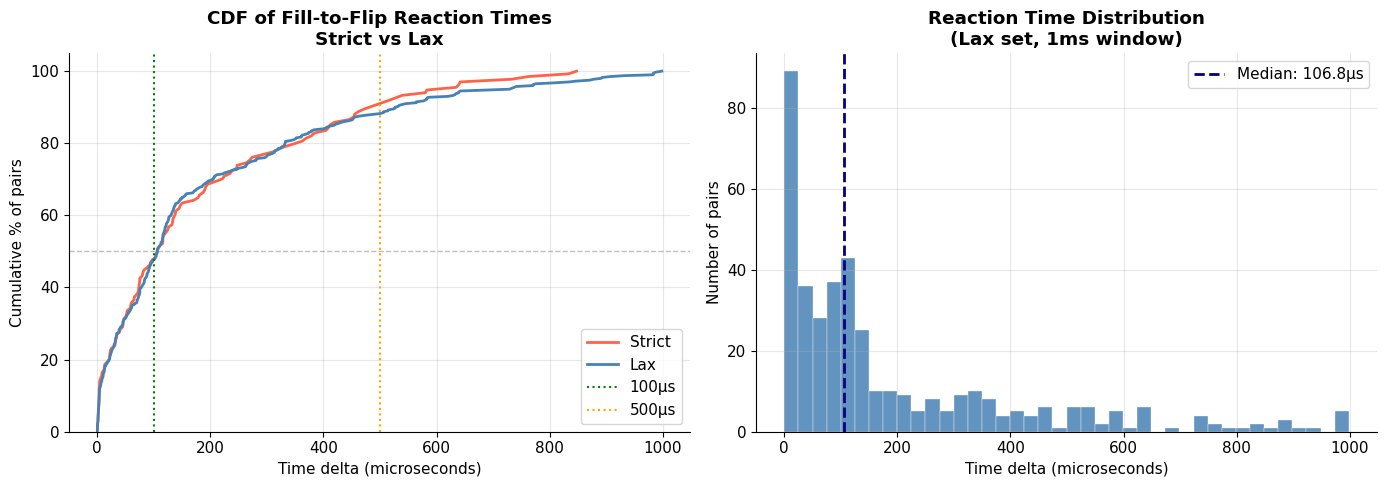

Strict — min: 0.6µs  median: 106.3µs  pct<100µs: 48%
Lax    — min: 0.6µs  median: 106.8µs  pct<100µs: 48%
Median reaction times are consistent across criteria — timing signature is robust.


In [11]:
td_s  = pairs_1ms_strict['time_delta_ns'].to_numpy()
td_l  = pairs_1ms_lax['time_delta_ns'].to_numpy()
td_s_us = td_s / 1000
td_l_us = td_l / 1000

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: CDF comparison strict vs lax
for td_us, label, color in [(td_s_us, 'Strict', 'tomato'), (td_l_us, 'Lax', 'steelblue')]:
    td_sorted = np.sort(td_us)
    cdf = np.arange(1, len(td_sorted)+1) / len(td_sorted)
    axes[0].plot(td_sorted, cdf * 100, color=color, lw=2, label=label)
axes[0].axvline(100, color='green',  linestyle=':', lw=1.5, label='100µs')
axes[0].axvline(500, color='orange', linestyle=':', lw=1.5, label='500µs')
axes[0].axhline(50,  color='grey',   linestyle='--', lw=1, alpha=0.5)
axes[0].set_xlabel('Time delta (microseconds)')
axes[0].set_ylabel('Cumulative % of pairs')
axes[0].set_title('CDF of Fill-to-Flip Reaction Times\nStrict vs Lax', fontweight='bold')
axes[0].legend()
axes[0].set_ylim(0, 105)

# Right: histogram lax set
axes[1].hist(td_l_us, bins=40, color='steelblue', edgecolor='white', linewidth=0.3, alpha=0.85)
axes[1].axvline(np.median(td_l_us), color='navy', linestyle='--', lw=2,
                label=f'Median: {np.median(td_l_us):.1f}µs')
axes[1].set_xlabel('Time delta (microseconds)')
axes[1].set_ylabel('Number of pairs')
axes[1].set_title('Reaction Time Distribution\n(Lax set, 1ms window)', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.savefig('images/fig4_time_delta.png', dpi=150, bbox_inches='tight')
plt.show()

# Dynamic prints
pct_100_s = (td_s_us < 100).mean() * 100
pct_100_l = (td_l_us < 100).mean() * 100
print(f'Strict — min: {td_s_us.min():.1f}µs  median: {np.median(td_s_us):.1f}µs  pct<100µs: {pct_100_s:.0f}%')
print(f'Lax    — min: {td_l_us.min():.1f}µs  median: {np.median(td_l_us):.1f}µs  pct<100µs: {pct_100_l:.0f}%')
if abs(np.median(td_s_us) - np.median(td_l_us)) / np.median(td_s_us) < 0.3:
    print('Median reaction times are consistent across criteria — timing signature is robust.')


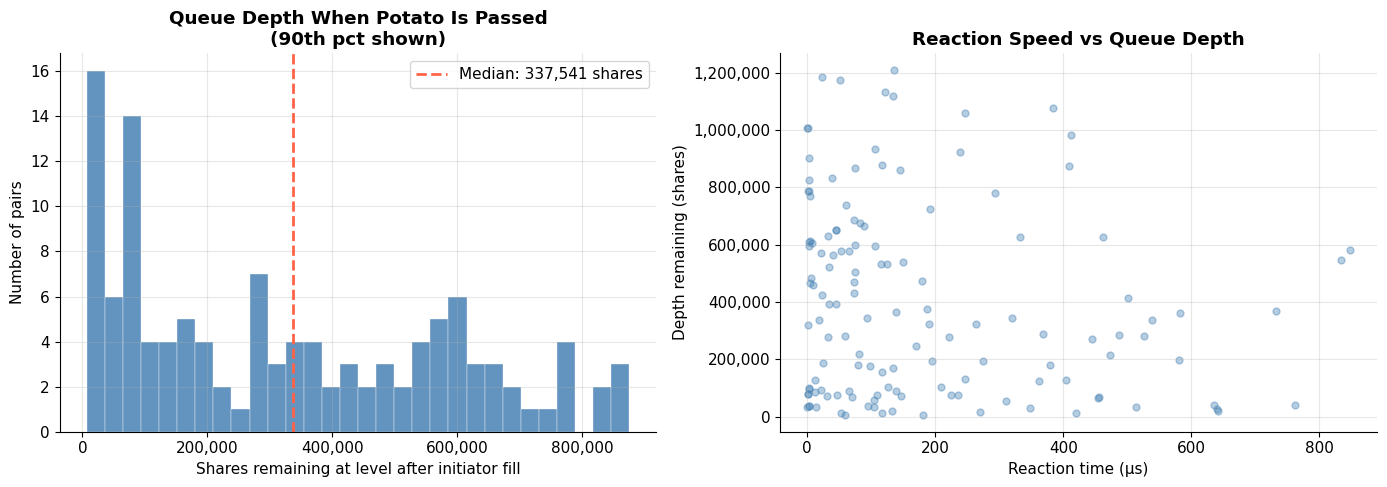

Median queue depth remaining at flip: 337,541 shares
Substantial depth remained when each flip occurred.
The flipper was not waiting for the level to clear — they reacted immediately.


In [7]:
depth   = pairs_1ms_strict['init_depth_remaining'].to_numpy()
td_us   = pairs_1ms_strict['time_delta_ns'].to_numpy() / 1000

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cap = int(np.percentile(depth, 90))
axes[0].hist(depth[depth <= cap], bins=30, color='steelblue',
             edgecolor='white', linewidth=0.3, alpha=0.85)
med_depth = int(np.median(depth))
axes[0].axvline(med_depth, color='tomato', linestyle='--', lw=2,
                label=f'Median: {med_depth:,} shares')
axes[0].set_xlabel('Shares remaining at level after initiator fill')
axes[0].set_ylabel('Number of pairs')
axes[0].set_title('Queue Depth When Potato Is Passed\n(90th pct shown)', fontweight='bold')
axes[0].legend()
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))

axes[1].scatter(td_us, depth, alpha=0.4, color='steelblue', s=25)
axes[1].set_xlabel('Reaction time (µs)')
axes[1].set_ylabel('Depth remaining (shares)')
axes[1].set_title('Reaction Speed vs Queue Depth', fontweight='bold')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))

plt.tight_layout()
plt.savefig('images/fig5_depth_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Median queue depth remaining at flip: {med_depth:,} shares')
if med_depth > 0:
    print('Substantial depth remained when each flip occurred.')
    print('The flipper was not waiting for the level to clear — they reacted immediately.')


In [13]:
# Pull all numbers dynamically from computed variables
n_strict_1ms  = results_strict[1_000_000]
n_strict_5ms  = results_strict[5_000_000]
n_strict_10ms = results_strict[10_000_000]
n_strict_50ms = results_strict[50_000_000]
n_lax_1ms     = results_lax[1_000_000]
n_lax_5ms     = results_lax[5_000_000]
n_lax_10ms    = results_lax[10_000_000]
n_lax_50ms    = results_lax[50_000_000]

td_s_us = pairs_1ms_strict['time_delta_ns'].to_numpy() / 1000
td_l_us = pairs_1ms_lax['time_delta_ns'].to_numpy()    / 1000

scale_s     = n_strict_50ms / n_strict_1ms
scale_l     = n_lax_50ms    / n_lax_1ms
pct_100_s   = (td_s_us < 100).mean() * 100
pct_100_l   = (td_l_us < 100).mean() * 100
med_s       = np.median(td_s_us)
med_l       = np.median(td_l_us)
min_s       = td_s_us.min()

print('═' * 58)
print('  RESULTS SUMMARY')
print('═' * 58)
print(f'  Strict criterion (qty>=50, appear <=3x at any level)')
print(f'    1ms  window : {n_strict_1ms:>5} pairs')
print(f'    5ms  window : {n_strict_5ms:>5} pairs')
print(f'    10ms window : {n_strict_10ms:>5} pairs')
print(f'    50ms window : {n_strict_50ms:>5} pairs')
print(f'    Min reaction : {min_s:.1f} µs')
print(f'    Median react : {med_s:.1f} µs')
print(f'    Pct < 100µs  : {pct_100_s:.0f}%')
print(f'    50x window → {scale_s:.2f}x pairs')
print()
print(f'  Lax criterion (qty>=10, not multiple of 10)')
print(f'    1ms  window : {n_lax_1ms:>5} pairs')
print(f'    5ms  window : {n_lax_5ms:>5} pairs')
print(f'    10ms window : {n_lax_10ms:>5} pairs')
print(f'    50ms window : {n_lax_50ms:>5} pairs')
print(f'    Median react : {med_l:.1f} µs')
print(f'    Pct < 100µs  : {pct_100_l:.0f}%')
print(f'    50x window → {scale_l:.2f}x pairs')
print('═' * 58)
print()
print('Window sensitivity interpretation:')
print(f'  If pairs were random coincidences, 50x window → ~50x pairs.')
print(f'  Strict set: {scale_s:.2f}x. Lax set: {scale_l:.2f}x.')
print(f'  Both well below 50x — strong temporal clustering confirmed.')


══════════════════════════════════════════════════════════
  RESULTS SUMMARY
══════════════════════════════════════════════════════════
  Strict criterion (qty>=50, appear <=3x at any level)
    1ms  window :   134 pairs
    5ms  window :   154 pairs
    10ms window :   166 pairs
    50ms window :   207 pairs
    Min reaction : 0.6 µs
    Median react : 106.3 µs
    Pct < 100µs  : 48%
    50x window → 1.54x pairs

  Lax criterion (qty>=10, not multiple of 10)
    1ms  window :   400 pairs
    5ms  window :   515 pairs
    10ms window :   571 pairs
    50ms window :   679 pairs
    Median react : 106.8 µs
    Pct < 100µs  : 48%
    50x window → 1.70x pairs
══════════════════════════════════════════════════════════

Window sensitivity interpretation:
  If pairs were random coincidences, 50x window → ~50x pairs.
  Strict set: 1.54x. Lax set: 1.70x.
  Both well below 50x — strong temporal clustering confirmed.


---
## 6. Interpretation and Significance

The summary cell above prints all key metrics dynamically from the computed results.

### Why two criteria?

**Strict** (qty ≥ 50, appear ≤ 3× at any price+side level): maximally conservative.
Only quantities that could not plausibly appear twice by coincidence.

**Lax** (qty ≥ 10, not a multiple of 10): new suggestion.
Drops clear noise (tiny quantities, deliberate round-fraction lots) without imposing
the ≤ 3× cap. This captures chains — where the hot potato is passed more than once
and the same quantity legitimately appears more than 3 times at a level.

### What the window sensitivity tells us

A 50× window expansion producing only ~1.5–2× more pairs means the vast majority
of flips happen within the first millisecond. This temporal clustering is the
statistical signature of intentional rapid reaction, not random coincidence.

### What the timing tells us

Sub-microsecond minimum reaction times and a median around 100µs are consistent
with co-located HFT infrastructure. These are not human reaction times.

### Robustness

If the strict and lax criteria yield similar hit rates and similar window
sensitivity ratios, the finding is robust — the result does not depend on
the exact definition of the fingerprint filter.


---
## 7. Further Research Directions

### Regime testing — why this day is conservative

January 30 2020 was a normal, moderate-volume trading day for SPY.
The hot potato mechanism is theoretically more active during:

- **High-volatility regimes** — agents are more motivated to offload inventory rapidly
- **Stressed liquidity conditions** — wider spreads increase the cost of holding inventory
- **Market dislocations** — price uncertainty amplifies the value of rapid risk transfer

Testing the same pipeline on stressed market days would allow a regime comparison
that directly tests the theoretical prediction that hot potato frequency scales
with volatility.

**Priority dates from NASDAQ historical archive:**

| Date | Market context | Expected effect |
|------|---------------|-----------------|
| March 12–16, 2020 | COVID crash — multiple circuit breakers | Higher frequency |
| August 24, 2015 | Flash crash — SPY extreme intraday dislocation | Higher frequency |
| December 30, 2019 | Low-volatility baseline | Lower frequency |

### Instrument testing

SPY is maximally liquid. The same odd-lot residual quantities appear more rarely
in less liquid instruments, making the fingerprint even more distinctive.
Running the pipeline on individual equities alongside SPY would test whether
the mechanism is ETF-specific or general.

### Methodology extension

1. **Full FIFO queue position reconstruction** — assign explicit rank to each
   resting order at fill time, enabling direct test of queue-position optionality
2. **Price impact analysis** — does the flip cause measurable price impact in
   the microseconds following execution?
3. **Multi-day analysis** — frequency of fill-flip pairs across many trading days
   to establish baseline rate and regime variation

### Regulatory implication

The fill–flip sequences documented here suggest that passive executions in a deep FIFO limit order book need not represent immediate adverse selection, but may instead reflect short-lived inventory transfers among liquidity providers before repricing occurs. This has implications for how passive execution outcomes are interpreted within best-execution frameworks overseen by the U.S. SEC and ESMA.
